# Finite difference solver for a BVP with a first derivative term

Companion notebook for Example 16.2 in `Lec16.tex`. We solve
$$
-u''(t) + \varepsilon u'(t) = f(t), \qquad u(0) = u(1) = 0,
$$
with $\varepsilon = 0.1$ and $f$ a narrow Gaussian bump of standard deviation $\sigma = 0.1$ centered at $t = 1/2$,
$$
f(t) = \exp\!\left(-\frac{(t - 1/2)^2}{2\sigma^2}\right).
$$

Following the three steps of the lecture:
- **Step 1:** uniform grid $t_n = n \Delta t$, $n = 0, \dots, N$, with $\Delta t = 1/N$.
- **Step 2:** centered difference for $u''$ and a forward difference for $u'$,
  $$
  -\frac{1}{\Delta t^2}(u_{n-1} - 2u_n + u_{n+1}) + \varepsilon \frac{1}{\Delta t}(u_{n+1} - u_n) = f_n.
  $$
- **Step 3:** with $A$ the centered difference matrix from Example 16.1 and $B$ the forward difference matrix (zero
  first and last rows), solve $D \mathbf{u} = \mathbf{f}$ with $D = -A + \varepsilon B$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf

In [2]:
sigma = 0.1
m = 0.5
eps = 2


def f(t):
    return np.exp(-((t - m) ** 2) / (2 * sigma**2))


def fd_solve(f, N):
    t = np.linspace(0, 1, N + 1)
    dt = 1 / N

    # centered difference matrix for u'' from Example 16.1, with boundary rows u_0 = u_N = 0
    A = np.zeros((N + 1, N + 1))
    A[0, 0] = 1
    A[N, N] = 1
    for n in range(1, N):
        A[n, n - 1] = 1 / dt**2
        A[n, n] = -2 / dt**2
        A[n, n + 1] = 1 / dt**2

    # forward difference matrix for u', zero in the boundary rows
    B = np.zeros((N + 1, N + 1))
    for n in range(1, N):
        B[n, n] = -1 / dt
        B[n, n + 1] = 1 / dt

    D = -A + eps * B
    b = f(t)
    # the boundary rows of D read -u_0 = 0 and -u_N = 0
    b[0], b[N] = 0, 0

    u = np.linalg.solve(D, b)
    return t, u

For reference we also compute the exact solution. Writing $v = u'$, the ODE becomes
$(e^{-\varepsilon t} v)' = -e^{-\varepsilon t} f$, so $v(t) = e^{\varepsilon t}\big(v_0 - G(t)\big)$ with
$G(t) = \int_0^t e^{-\varepsilon s} f(s)\, ds$. Completing the square in the exponent,
$e^{-\varepsilon s} f(s) = K \exp\!\big(-\frac{(s - m')^2}{2\sigma^2}\big)$ with $m' = m - \varepsilon \sigma^2$ and
$K = e^{-\varepsilon m + \varepsilon^2 \sigma^2 / 2}$, so
$$
G(t) = K \sigma \sqrt{\tfrac{\pi}{2}} \left[\mathrm{erf}\!\left(\frac{t - m'}{\sqrt{2}\sigma}\right) - \mathrm{erf}\!\left(\frac{-m'}{\sqrt{2}\sigma}\right)\right],
\qquad
F(t) = \int_0^t f(s)\, ds = \sigma \sqrt{\tfrac{\pi}{2}} \left[\mathrm{erf}\!\left(\frac{t - m}{\sqrt{2}\sigma}\right) - \mathrm{erf}\!\left(\frac{-m}{\sqrt{2}\sigma}\right)\right].
$$
Integrating $v$ once more (by parts) and imposing $u(0) = u(1) = 0$ gives
$$
u(t) = \frac{1}{\varepsilon}\Big( v_0 (e^{\varepsilon t} - 1) - e^{\varepsilon t} G(t) + F(t) \Big),
\qquad v_0 = \frac{e^{\varepsilon} G(1) - F(1)}{e^{\varepsilon} - 1}.
$$

In [3]:
m_shift = m - eps * sigma**2
K = np.exp(-eps * m + eps**2 * sigma**2 / 2)


def G(t):
    return K * sigma * np.sqrt(np.pi / 2) * (erf((t - m_shift) / (np.sqrt(2) * sigma)) - erf(-m_shift / (np.sqrt(2) * sigma)))


def F(t):
    return sigma * np.sqrt(np.pi / 2) * (erf((t - m) / (np.sqrt(2) * sigma)) - erf(-m / (np.sqrt(2) * sigma)))


v0 = (np.exp(eps) * G(1) - F(1)) / (np.exp(eps) - 1)


def u_exact(t):
    return (v0 * (np.exp(eps * t) - 1) - np.exp(eps * t) * G(t) + F(t)) / eps

N =   4: max error = 2.993e-02
N =   8: max error = 7.520e-03
N =  16: max error = 3.226e-03


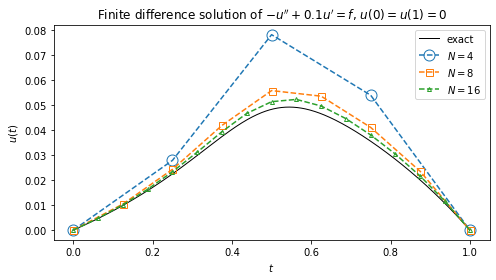

In [4]:
t_fine = np.linspace(0, 1, 500)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t_fine, u_exact(t_fine), "k-", linewidth=1, label="exact")
# nested grids share points, so use hollow markers of decreasing size to keep all visible
for N, marker, ms in zip([4, 8, 16], ["o", "s", "^"], [11, 7, 4]):
    t, u = fd_solve(f, N)
    err = np.max(np.abs(u - u_exact(t)))
    print(f"N = {N:3d}: max error = {err:.3e}")
    ax.plot(t, u, marker=marker, linestyle="--", markersize=ms, markerfacecolor="none", label=rf"$N = {N}$")
ax.set_xlabel(r"$t$")
ax.set_ylabel(r"$u(t)$")
ax.set_title(r"Finite difference solution of $-u'' + 0.1 u' = f$, $u(0) = u(1) = 0$")
ax.legend()
fig.tight_layout()
fig.savefig("fd_advection_bvp.png", dpi=300, bbox_inches="tight")
plt.show()

## Convergence study

We measure the maximum error $E_N = \max_n |u_n - u(t_n)|$ over a sequence of grids $N = 4, 8, \dots, 2048$.
If $E_N \approx C N^{-p}$ then $\log E_N \approx \log C - p \log N$, so the rate $p$ is minus the slope of the
error on a log-log plot. We estimate $p$ in two ways: from the ratio of successive errors,
$p \approx \log_2(E_N / E_{2N})$, and from a least squares fit of a line to $(\log N, \log E_N)$.

In [5]:
Ns = 2 ** np.arange(2, 12)
errs = np.array([np.max(np.abs(u - u_exact(t))) for t, u in (fd_solve(f, N) for N in Ns)])

# observed rate between successive grids
rates = np.log2(errs[:-1] / errs[1:])
print(f"{'N':>6} {'max error':>12} {'rate':>6}")
print(f"{Ns[0]:6d} {errs[0]:12.3e}")
for N, e, r in zip(Ns[1:], errs[1:], rates):
    print(f"{N:6d} {e:12.3e} {r:6.2f}")

# least squares fit of log(err) = log(C) - p log(N) over the fine grids, where the first order term dominates
fit = Ns >= 256
slope, intercept = np.polyfit(np.log(Ns[fit]), np.log(errs[fit]), 1)
p = -slope
print(f"\nfitted rate of convergence (N >= 256): p = {p:.3f}")

     N    max error   rate
     4    2.993e-02
     8    7.520e-03   1.99
    16    3.226e-03   1.22
    32    1.483e-03   1.12
    64    7.136e-04   1.06
   128    3.500e-04   1.03
   256    1.734e-04   1.01
   512    8.627e-05   1.01
  1024    4.304e-05   1.00
  2048    2.149e-05   1.00

fitted rate of convergence (N >= 256): p = 1.004


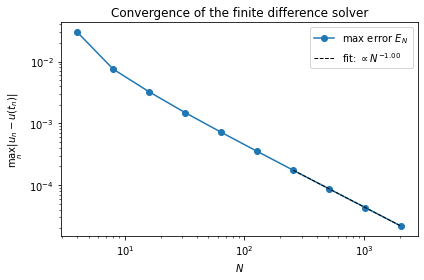

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(Ns, errs, "o-", label=r"max error $E_N$")
ax.loglog(Ns[fit], np.exp(intercept) * Ns[fit].astype(float) ** slope, "k--", linewidth=1, label=rf"fit: $\propto N^{{-{p:.2f}}}$")
ax.set_xlabel(r"$N$")
ax.set_ylabel(r"$\max_n |u_n - u(t_n)|$")
ax.set_title("Convergence of the finite difference solver")
ax.legend()
fig.tight_layout()
fig.savefig("fd_advection_bvp_convergence.png", dpi=300, bbox_inches="tight")
plt.show()